# Задание 4.6

Два лица $A$ и $B$ условились встретиться в определённом месте между двумя и тремя часами дня. Лицо $A$ ждёт другого в течение 10 минут, после чего уходит; лицо $B$ ждёт другого в течение 12 минут. Считая, что момент прихода на встречу выбирается каждым «наудачу» в пределах указанного часа, найдите вероятность, что встреча состоится. Постройте график зависимости относительной частоты $\hat p(A)=\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N=150\,000$ и приведите оценку вероятности $\hat p(A)=\dfrac{N_A}{N}$ для $N=150\,000$.

**Ответ:** $0{,}332778$ (оценка вероятности $\hat p=0{,}33268$).

*Общее требование листка:* ко всем задачам, где есть числовой ответ, напишите программу (код) с использованием инструментария **Jupyter Notebook**, который иллюстрирует график зависимости относительной частоты $\hat p(A)\overset{\text{def}}{=}\dfrac{N(A)}{N}$ события $A$ от числа проведённых реализаций опыта $N$.

## Теория

**Геометрическое определение вероятности.** Если исход — точка, брошенная «наудачу» в область $\Omega$ (равномерно), то

$$
\mathbb P(A)=\frac{\mu(A)}{\mu(\Omega)},
$$

где $\mu$ — длина, площадь или объём.

**Модель.** Пусть $x$ — момент прихода лица $A$, $y$ — лица $B$ (в минутах после 14:00). Тогда $\Omega=[0,60]^2$, $\mu(\Omega)=3600$.

**Событие «встреча состоится».**
- если первым пришёл $A$ ($x\le y$), он ждёт 10 минут: нужно $y-x\le10$;
- если первым пришёл $B$ ($y<x$), он ждёт 12 минут: нужно $x-y\le12$.

$$
M=\{(x,y)\in\Omega:\ -12\le y-x\le 10\}.
$$

Это полоса вокруг диагонали. Дополнение к ней — два прямоугольных треугольника с катетами $60-10=50$ и $60-12=48$:

$$
\mu(M)=3600-\frac{50^2}{2}-\frac{48^2}{2}=3600-1250-1152=1198,\qquad
\mathbb P(M)=\frac{1198}{3600}=\frac{599}{1800}\approx0{,}332778 .
$$

**Моделирование:** генерируем $N=150\,000$ точек $(x,y)$, равномерно распределённых в квадрате, и считаем долю попавших в полосу.

P(встреча) = 599/1800 = 0.332778


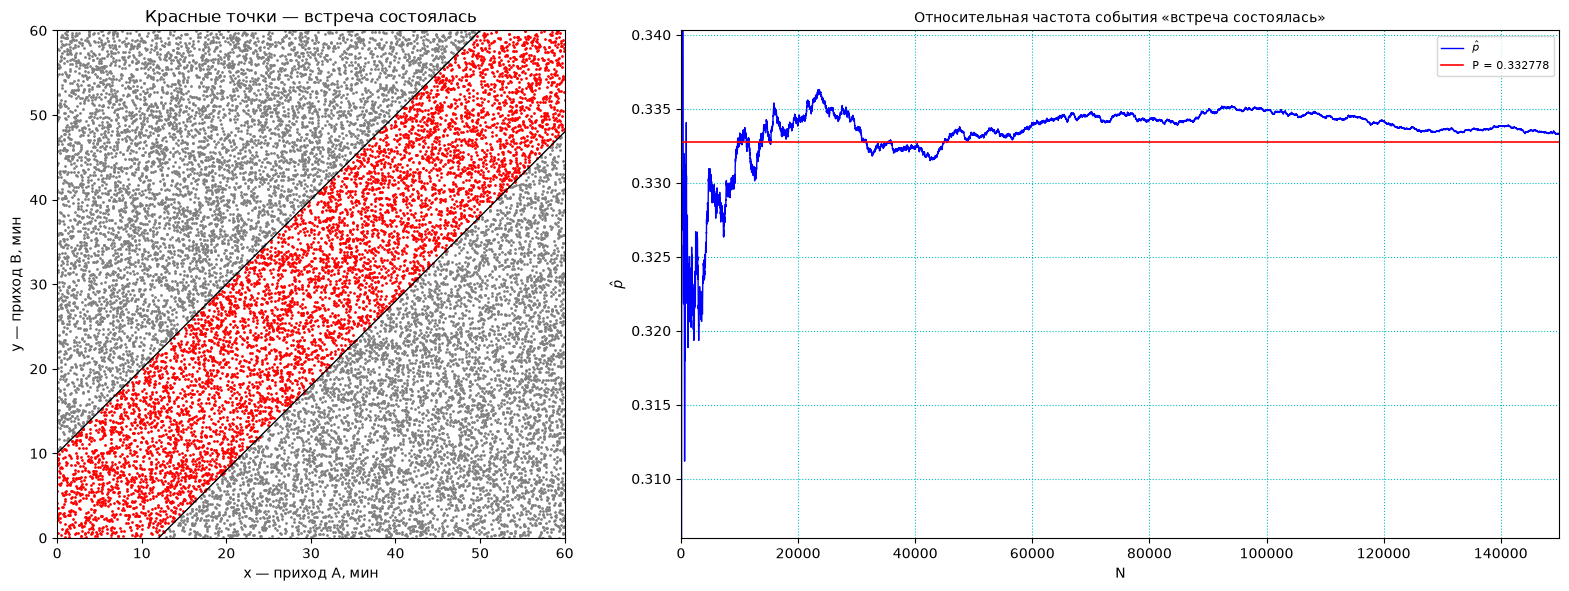

Оценка p̂ = N_A/N = 49997/150000 = 0.33331;  |p̂ - P| = 5.36e-04


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction

rng = np.random.default_rng(2026)

def plot_freq(ax, hits, p, title, cond=None, skip=None):
    """График относительной частоты p̂ = N(A)/N от числа опытов N (красная линия — точная вероятность p).
    Если задано cond — строится условная частота N(A∩B)/N(B)."""
    hits = np.asarray(hits, dtype=bool)
    n = np.arange(1, hits.size + 1)
    if cond is None:
        freq = np.cumsum(hits) / n                                   # p̂(A) после каждого опыта
    else:
        nb = np.cumsum(cond)
        freq = np.where(nb > 0, np.cumsum(hits & cond) / np.maximum(nb, 1), np.nan)  # p̂(A|B)
    step = max(1, hits.size // 20000)                                # прореживаем точки для отрисовки
    ax.plot(n[::step], freq[::step], color="blue", lw=1, label=r"$\hat p$")
    ax.axhline(p, color="red", lw=1.2, label=f"P = {p:.6f}")
    skip = skip or max(50, hits.size // 300)                         # первые опыты — сильный разброс
    lo, hi = np.nanmin(freq[skip:]), np.nanmax(freq[skip:])
    lo, hi = min(lo, p), max(hi, p)
    pad = 0.15 * (hi - lo) + 1e-12
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, hits.size)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("N")
    ax.set_ylabel(r"$\hat p$")
    ax.grid(ls=":", color="c")
    ax.legend(fontsize=8, loc="upper right")
    return freq[-1]


# ---------- Точная вероятность (отношение площадей) ----------
T, wA, wB = 60, 10, 12
P = Fraction(T**2 - Fraction((T - wA)**2, 2) - Fraction((T - wB)**2, 2), T**2)
print(f"P(встреча) = {P} = {float(P):.6f}")

# ---------- Моделирование ----------
N = 150_000
x = rng.uniform(0, T, N)                          # приход A
y = rng.uniform(0, T, N)                          # приход B
meet = (y - x <= wA) & (x - y <= wB)              # A ждёт 10 мин, B ждёт 12 мин

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.6]})
s = slice(0, 20_000)                              # для наглядности рисуем 20 000 точек
axes[0].scatter(x[s][~meet[s]], y[s][~meet[s]], s=1, c="gray", rasterized=True)
axes[0].scatter(x[s][meet[s]], y[s][meet[s]], s=1, c="red", rasterized=True)
xx = np.linspace(0, T, 2)
axes[0].plot(xx, xx + wA, "k", lw=1); axes[0].plot(xx, xx - wB, "k", lw=1)
axes[0].set_xlim(0, T); axes[0].set_ylim(0, T); axes[0].set_aspect("equal")
axes[0].set_xlabel("x — приход A, мин"); axes[0].set_ylabel("y — приход B, мин")
axes[0].set_title("Красные точки — встреча состоялась")

ph = plot_freq(axes[1], meet, float(P), "Относительная частота события «встреча состоялась»")
fig.tight_layout()
plt.show()

print(f"Оценка p̂ = N_A/N = {meet.sum()}/{N} = {ph:.5f};  |p̂ - P| = {abs(ph - float(P)):.2e}")